In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["font.family"] = "Hiragino Sans"  # 日本語表示用（macOS）

PROJECT_DIR = Path.home() / "applied_programming_ii" / "06"
DATA_DIR = Path.home() / "applied_programming_ii" / "data"
FIGURE_DIR = PROJECT_DIR / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("作業フォルダ:", PROJECT_DIR)
print("ダムデータの有無:", (DATA_DIR / "dam_urayama_daily.csv").exists())

作業フォルダ: /Users/kkagawa/applied_programming_ii/06
ダムデータの有無: True


In [2]:
dam = pd.read_csv(DATA_DIR / "dam_urayama_daily.csv", parse_dates=["date"])

In [5]:
print(dam.head())
print(dam.tail())

        date  water_level_m  inflow_m3s  outflow_m3s
0 2015-01-01         380.37        0.72         0.72
1 2015-01-02         380.37        0.72         0.72
2 2015-01-03         380.37        0.72         0.72
3 2015-01-04         380.37        0.72         0.72
4 2015-01-05         380.37        0.72         0.72
           date  water_level_m  inflow_m3s  outflow_m3s
3282 2023-12-27         370.43        0.58         1.52
3283 2023-12-28         370.34        0.48         1.52
3284 2023-12-29         370.24        0.48         1.51
3285 2023-12-30         370.14        0.58         1.51
3286 2023-12-31         370.04        0.47         1.51


In [6]:
print("期間:", dam["date"].min().date(), "〜", dam["date"].max().date(), " 行数:", len(dam))
print("欠損値の数:")
print(dam.isna().sum())

期間: 2015-01-01 〜 2023-12-31  行数: 3287
欠損値の数:
date             0
water_level_m    0
inflow_m3s       0
outflow_m3s      0
dtype: int64


In [9]:
intervals = dam["date"].diff().dt.days
intervals = intervals.dropna()
interval_types = intervals.unique().tolist()
print("日付の間隔（日）の種類:", sorted(interval_types))

日付の間隔（日）の種類: [1.0]


In [11]:
year = 2019
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
dam_year

,date,water_level_m,inflow_m3s,outflow_m3s
0,2019-01-01,382.58,0.61,0.73
1,2019-01-02,382.57,0.61,0.73
2,2019-01-03,382.55,0.48,0.73
3,2019-01-04,382.53,0.48,0.73
4,2019-01-05,382.52,0.61,0.73
...,...,...,...,...
360,2019-12-27,391.92,1.06,0.78
361,2019-12-28,391.94,1.06,0.78
362,2019-12-29,391.96,0.92,0.78
363,2019-12-30,391.97,1.06,0.78


In [12]:
print(f"対象年: {year}年，観測日数: {len(dam_year)}日")
inflow_max_index = dam_year["inflow_m3s"].idxmax()
outflow_max_index = dam_year["outflow_m3s"].idxmax()
inflow_max_date = dam_year.loc[inflow_max_index, "date"].date()
outflow_max_date = dam_year.loc[outflow_max_index, "date"].date()
print("流入量の最大値:", dam_year["inflow_m3s"].max(), "m^3/s  日付:", inflow_max_date)
print("放流量の最大値:", dam_year["outflow_m3s"].max(), "m^3/s  日付:", outflow_max_date)

対象年: 2019年，観測日数: 365日
流入量の最大値: 201.11 m^3/s  日付: 2019-10-12
放流量の最大値: 126.62 m^3/s  日付: 2019-10-13


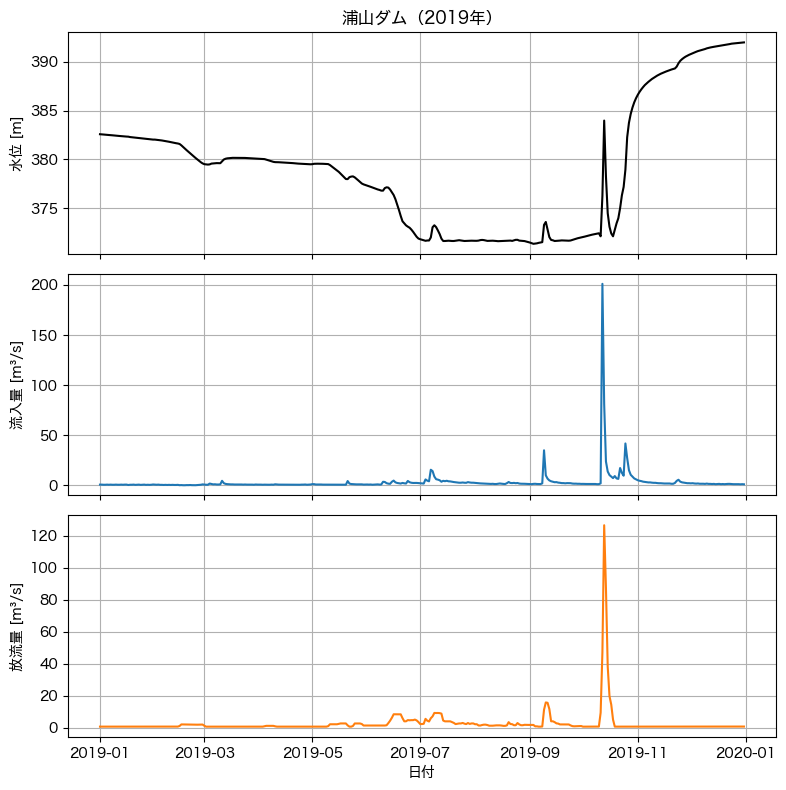

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
axes[0].plot(dam_year["date"], dam_year["water_level_m"], color="black")
axes[0].set_ylabel("水位 [m]")
axes[0].set_title(f"浦山ダム（{year}年）")
axes[1].plot(dam_year["date"], dam_year["inflow_m3s"], color="tab:blue", label="流入量")
axes[1].set_ylabel("流入量 [m³/s]")
axes[2].plot(dam_year["date"], dam_year["outflow_m3s"], color="tab:orange", label="放流量")
axes[2].set_ylabel("放流量 [m³/s]")
axes[2].set_xlabel("日付")
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"dam_observed_{year}.png", dpi=150)
plt.show()

In [14]:
SECONDS_PER_DAY = 24 * 60 * 60


def m3s_to_1000m3_per_day(flow_m3s):
    """流量 [m^3/s] を [千m^3/日] に換算する．"""
    return flow_m3s * SECONDS_PER_DAY / 1000

In [15]:
V_EFFECTIVE = 56000.0   # 有効貯水容量 [千m^3]

q_max = dam_year["inflow_m3s"].max()
q_max_daily = m3s_to_1000m3_per_day(q_max)

In [16]:
print(f"最大流入量 {q_max:.2f} m^3/s = {q_max_daily:.1f} 千m^3/日")
print(f"有効貯水容量に対する割合: {100 * q_max_daily / V_EFFECTIVE:.1f} %")
print(f"流入量 1.0 m^3/s = {m3s_to_1000m3_per_day(1.0):.1f} 千m^3/日")

最大流入量 201.11 m^3/s = 17375.9 千m^3/日
有効貯水容量に対する割合: 31.0 %
流入量 1.0 m^3/s = 86.4 千m^3/日


In [17]:
flow = 3.5
days = 7
flow_daily = m3s_to_1000m3_per_day(flow)
inflow_volume = flow_daily * days
volume_percent = 100 * inflow_volume / V_EFFECTIVE

In [18]:
print(f"7日分の流入水量: {inflow_volume:.1f} 千m^3")
print(f"有効貯水容量に対する割合: {volume_percent:.2f} %")

7日分の流入水量: 2116.8 千m^3
有効貯水容量に対する割合: 3.78 %


In [19]:
LEVEL_MIN = 304.0     # 最低水位 [m]
LEVEL_FULL = 393.3    # 常時満水位 [m]


def level_to_volume(level_m):
    """貯水位 [m] を貯水量 [千m^3] に換算する．最低水位と常時満水位の間で線形とみなす近似．"""
    return V_EFFECTIVE * (level_m - LEVEL_MIN) / (LEVEL_FULL - LEVEL_MIN)

In [20]:
slope = V_EFFECTIVE / (LEVEL_FULL - LEVEL_MIN)
print(f"貯水位1 mあたりの貯水量（線形近似）: {slope:.1f} 千m^3/m")
for level in [304.0, 350.0, 372.0, 393.3]:
    print(f"貯水位 {level:6.1f} m -> 貯水量 {level_to_volume(level):8.1f} 千m^3")

貯水位1 mあたりの貯水量（線形近似）: 627.1 千m^3/m
貯水位  304.0 m -> 貯水量      0.0 千m^3
貯水位  350.0 m -> 貯水量  28846.6 千m^3
貯水位  372.0 m -> 貯水量  42642.8 千m^3
貯水位  393.3 m -> 貯水量  56000.0 千m^3


In [21]:
dam_year["volume_1000m3"] = level_to_volume(dam_year["water_level_m"])

In [22]:
print(dam_year[["date", "water_level_m", "volume_1000m3"]].head())

        date  water_level_m  volume_1000m3
0 2019-01-01         382.58   49277.491601
1 2019-01-02         382.57   49271.220605
2 2019-01-03         382.55   49258.678611
3 2019-01-04         382.53   49246.136618
4 2019-01-05         382.52   49239.865622


In [23]:
V_start = level_to_volume(372.0)
V_end = level_to_volume(382.0)
volume_change = V_end - V_start

In [24]:
print(f"水位372 mでの貯水量: {V_start:.1f} 千m^3")
print(f"水位382 mでの貯水量: {V_end:.1f} 千m^3")
print(f"貯水量の増加: {volume_change:.1f} 千m^3")

水位372 mでの貯水量: 42642.8 千m^3
水位382 mでの貯水量: 48913.8 千m^3
貯水量の増加: 6271.0 千m^3


In [25]:
flow = 3.5
flow_daily = m3s_to_1000m3_per_day(flow)
required_days = volume_change / flow_daily

In [26]:
print(f"水位372 mから382 mまでに必要な日数: {required_days:.2f} 日")

水位372 mから382 mまでに必要な日数: 20.74 日


In [27]:
t_example = np.array([0.0, 1.0])
q_example = np.array([80.0, 120.0])
t_mid = 0.5

In [28]:
slope = (q_example[1] - q_example[0]) / (t_example[1] - t_example[0])
q_formula = q_example[0] + slope * (t_mid - t_example[0])
q_interp = np.interp(t_mid, t_example, q_example)

In [29]:
print(f"式による補間値: {q_formula:.1f} 千m^3/日")
print(f"np.interpによる補間値: {q_interp:.1f} 千m^3/日")

式による補間値: 100.0 千m^3/日
np.interpによる補間値: 100.0 千m^3/日


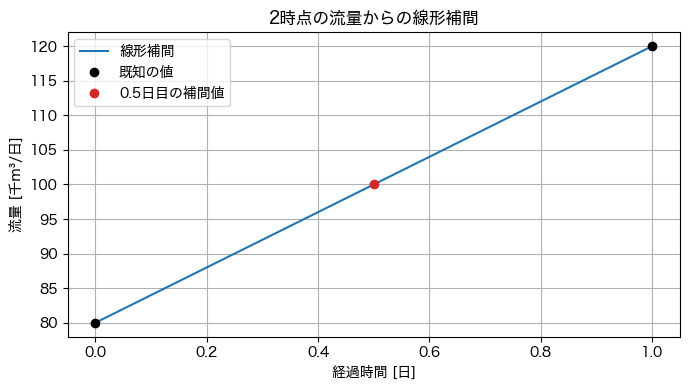

In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_example, q_example, color="tab:blue", label="線形補間")
ax.plot(t_example, q_example, "o", color="black", label="既知の値")
ax.plot(t_mid, q_interp, "o", color="tab:red", label="0.5日目の補間値")
ax.set_title("2時点の流量からの線形補間")
ax.set_xlabel("経過時間 [日]")
ax.set_ylabel("流量 [千m³/日]")
ax.grid(True)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "linear_interpolation.png", dpi=150)
plt.show()

In [31]:
def reservoir_rhs(t, V, t_data, qin_data, qout_data):
    """dV/dt = Q_in(t) - Q_out(t) の右辺．流入量と放流量は観測値を線形補間して使う．

    t_data: 観測時刻の配列 [日]
    qin_data, qout_data: 観測された流入量と放流量の配列 [千m^3/日]
    """
    q_in = np.interp(t, t_data, qin_data)
    q_out = np.interp(t, t_data, qout_data)
    return q_in - q_out

In [32]:
# 2日分の仮の入力で，中間時刻の補間を確認する．
t_example = np.array([0.0, 1.0])
qin_example = np.array([80.0, 120.0])
qout_example = np.array([60.0, 80.0])
rate_example = reservoir_rhs(0.5, 100.0, t_example, qin_example, qout_example)

In [33]:
print(f"0.5日後の貯水量の変化率: {rate_example:.1f} 千m^3/日")

0.5日後の貯水量の変化率: 30.0 千m^3/日


In [34]:
month_mask = (dam["date"] >= "2019-10-01") & (dam["date"] <= "2019-10-31")
month = dam[month_mask].reset_index(drop=True)
month.head()

,date,water_level_m,inflow_m3s,outflow_m3s
0,2019-10-01,372.03,1.35,0.72
1,2019-10-02,372.09,1.25,0.72
2,2019-10-03,372.14,1.25,0.72
3,2019-10-04,372.19,1.25,0.72
4,2019-10-05,372.24,1.25,0.72


In [35]:
# 観測値をモデルの単位に揃える
t_obs = np.arange(len(month), dtype=float)                       # 10月1日を0とした日数 [日]
qin_obs = m3s_to_1000m3_per_day(month["inflow_m3s"].values)      # [千m^3/日]
qout_obs = m3s_to_1000m3_per_day(month["outflow_m3s"].values)    # [千m^3/日]
V_obs = level_to_volume(month["water_level_m"].values)           # [千m^3]
print("t_obs:", t_obs[:5])
print("qin_obs:", qin_obs[:5])
print("qout_obs:", qout_obs[:5])
print("V_obs:", V_obs[:5])

t_obs: [0. 1. 2. 3. 4.]
qin_obs: [116.64 108.   108.   108.   108.  ]
qout_obs: [62.208 62.208 62.208 62.208 62.208]
V_obs: [42661.59014558 42699.21612542 42730.57110862 42761.92609183
 42793.28107503]


In [36]:
# 初期条件と計算区間
V0 = V_obs[0]
t_span = (t_obs[0], t_obs[-1])

In [37]:
sol = solve_ivp(
    reservoir_rhs,
    t_span,
    [V0],
    t_eval=t_obs,
    args=(t_obs, qin_obs, qout_obs),
    max_step=1.0,
)
V_model = sol.y[0]

In [38]:
print("成功したか:", sol.success)
print(f"{'日付':>12} {'流入':>8} {'放流':>8} {'モデルV':>9} {'換算V':>9} {'差':>8}")
for i in range(8, 18):
    date = str(month["date"][i].date())
    difference = V_model[i] - V_obs[i]
    print(f"{date:>12} {qin_obs[i]:8.0f} {qout_obs[i]:8.0f} {V_model[i]:9.0f} {V_obs[i]:9.0f} {difference:8.0f}")

成功したか: True
          日付       流入       放流      モデルV       換算V        差
  2019-10-09       90       62     43004     42894      111
  2019-10-10       93       67     43026     42912      114
  2019-10-11      162      816     42822     42718      104
  2019-10-12    17376     4079     48915     45320     3595
  2019-10-13     6994    10940     53694     50155     3539
  2019-10-14     2049     7550     49015     46575     2440
  2019-10-15     1184     3307     45189     44204      985
  2019-10-16      876     1712     43702     43333      369
  2019-10-17      742     1250     43032     42900      132
  2019-10-18      616      444     42863     42718      145


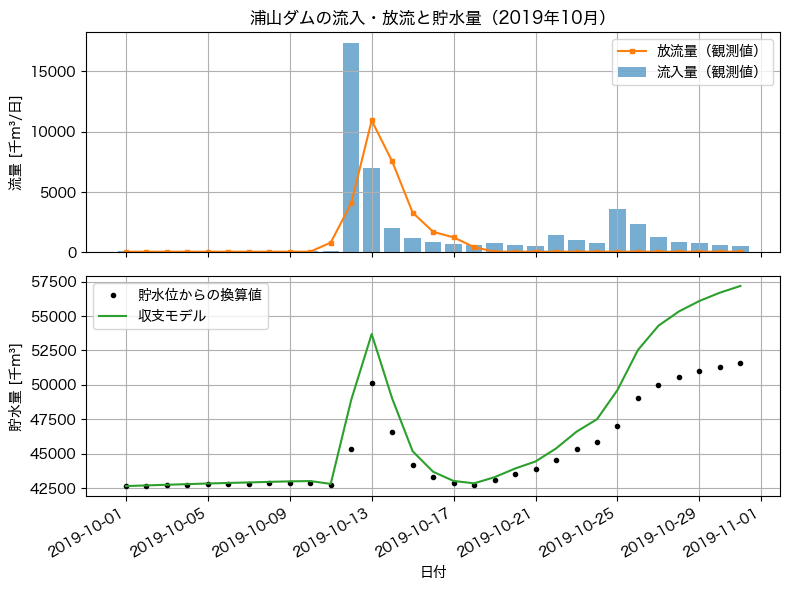

In [39]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].bar(month["date"], qin_obs, color="tab:blue", alpha=0.6, label="流入量（観測値）")
axes[0].plot(month["date"], qout_obs, color="tab:orange", marker="s", markersize=3, label="放流量（観測値）")
axes[0].set_ylabel("流量 [千m³/日]")
axes[0].set_title("浦山ダムの流入・放流と貯水量（2019年10月）")
axes[0].legend()
axes[1].plot(month["date"], V_obs, color="black", marker="o", markersize=3, linestyle="none", label="貯水位からの換算値")
axes[1].plot(month["date"], V_model, color="tab:green", label="収支モデル")
axes[1].set_ylabel("貯水量 [千m³]")
axes[1].set_xlabel("日付")
axes[1].legend()
for ax in axes:
    ax.grid(True)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "reservoir_october_2019.png", dpi=150)
plt.show()